In [ ]:
import pandas as pd

df = pd.read_csv("../dataset/survey.csv")

df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [3]:
df.shape

(1259, 27)

In [5]:
df.columns

Index(['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed',
       'family_history', 'treatment', 'work_interfere', 'no_employees',
       'remote_work', 'tech_company', 'benefits', 'care_options',
       'wellness_program', 'seek_help', 'anonymity', 'leave',
       'mental_health_consequence', 'phys_health_consequence', 'coworkers',
       'supervisor', 'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence', 'comments'],
      dtype='object')

In [7]:
df.isnull().sum()

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         515
self_employed                  18
family_history                  0
treatment                       0
work_interfere                264
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1095
dtype: int64

In [9]:
df.describe()

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


In [23]:
df = df[(df['Age'] >= 18) & (df['Age'] <= 60)]

In [25]:
df['self_employed'] = df['self_employed'].fillna('No')

df['work_interfere'] = df['work_interfere'].fillna(df['work_interfere'].mode()[0])

In [27]:
df.drop(columns=['state'], inplace=True)

In [29]:
df.isnull().sum()

Timestamp                    0
Age                          0
Gender                       0
Country                      0
self_employed                0
family_history               0
treatment                    0
work_interfere               0
no_employees                 0
remote_work                  0
tech_company                 0
benefits                     0
care_options                 0
wellness_program             0
seek_help                    0
anonymity                    0
leave                        0
mental_health_consequence    0
phys_health_consequence      0
coworkers                    0
supervisor                   0
mental_health_interview      0
phys_health_interview        0
mental_vs_physical           0
obs_consequence              0
dtype: int64

In [31]:
df['Gender'].unique()

array(['Female', 'M', 'Male', 'male', 'female', 'm', 'Male-ish', 'maile',
       'Trans-female', 'Cis Female', 'F', 'something kinda male?',
       'Cis Male', 'Woman', 'f', 'Mal', 'Male (CIS)', 'queer/she/they',
       'non-binary', 'Femake', 'woman', 'Make', 'Nah', 'Enby', 'fluid',
       'Genderqueer', 'Female ', 'Androgyne', 'Agender',
       'cis-female/femme', 'Guy (-ish) ^_^', 'male leaning androgynous',
       'Male ', 'Man', 'Trans woman', 'msle', 'Neuter', 'Female (trans)',
       'queer', 'Female (cis)', 'Mail', 'cis male', 'Malr', 'femail',
       'Cis Man', 'ostensibly male, unsure what that really means'],
      dtype=object)

In [ ]:
male_terms = ['male', 'm', 'male-ish', 'maile', 'mal', 'male (cis)', 
              'make', 'man', 'msle', 'mail', 'malr', 'cis man', 
              'cis male']

female_terms = ['cis female', 'f', 'female', 'woman', 'femake', 
                'female ', 'cis-female/femme', 'female (cis)', 'femail']

trans_terms = ['trans-female', 'something kinda male?', 'queer/she/they', 
               'non-binary', 'nah', 'all', 'enby', 'fluid', 'genderqueer', 
               'androgyne', 'agender', 'male leaning androgynous', 
               'travesti', 'guy (-ish) ^_^', 'neuter', 'female (trans)', 
               'queer', 'ostensibly male, unsure what that really means']

def clean_gender(gender):
    gender = str(gender).lower().strip()

    if gender in male_terms:
        return 'Male'
    elif gender in female_terms:
        return 'Female'
    else:
        return 'Other'

df['Gender'] = df['Gender'].apply(clean_gender)

In [35]:
df['Gender'].value_counts()

Gender
Male      983
Female    246
Other      18
Name: count, dtype: int64

In [37]:
from sklearn.preprocessing import LabelEncoder

In [39]:
label_encoder = LabelEncoder()

In [41]:
for column in df.columns:
    if df[column].dtype == 'object':
        df[column] = label_encoder.fit_transform(df[column])

In [43]:
df.head()

,Timestamp,Age,Gender,Country,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence
0,0,37,0,44,0,0,1,1,4,0,...,2,2,1,1,1,2,1,0,2,0
1,1,44,1,44,0,0,0,2,5,0,...,0,0,0,1,0,0,1,1,0,0
2,2,32,1,6,0,0,0,2,4,0,...,0,1,1,1,2,2,2,2,1,0
3,3,31,1,43,0,1,1,1,2,0,...,1,1,2,2,1,0,0,0,1,1
4,4,31,1,44,0,0,0,0,1,1,...,0,0,1,1,1,2,2,2,0,0


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

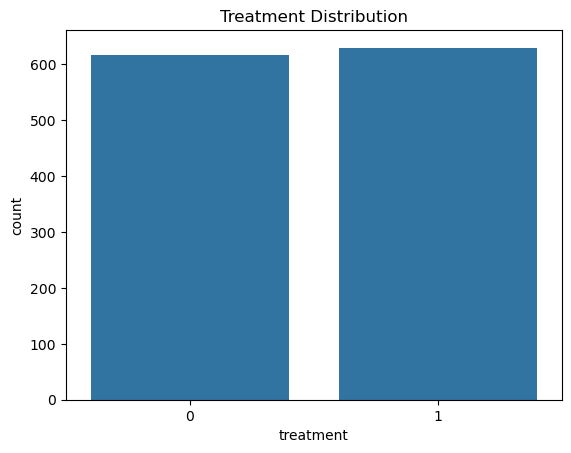

In [48]:
sns.countplot(x='treatment', data=df)

plt.title("Treatment Distribution")

plt.show()

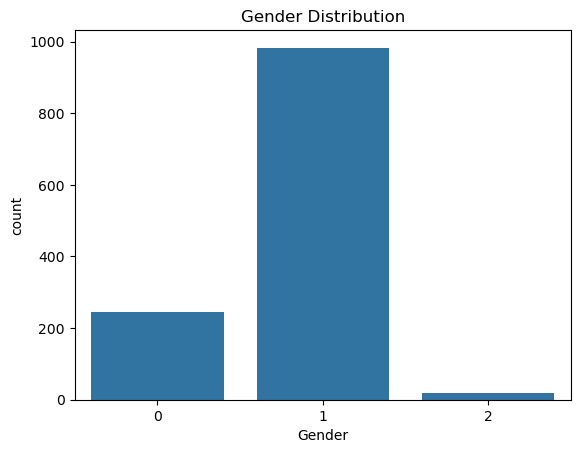

In [50]:
sns.countplot(x='Gender', data=df)

plt.title("Gender Distribution")

plt.show()

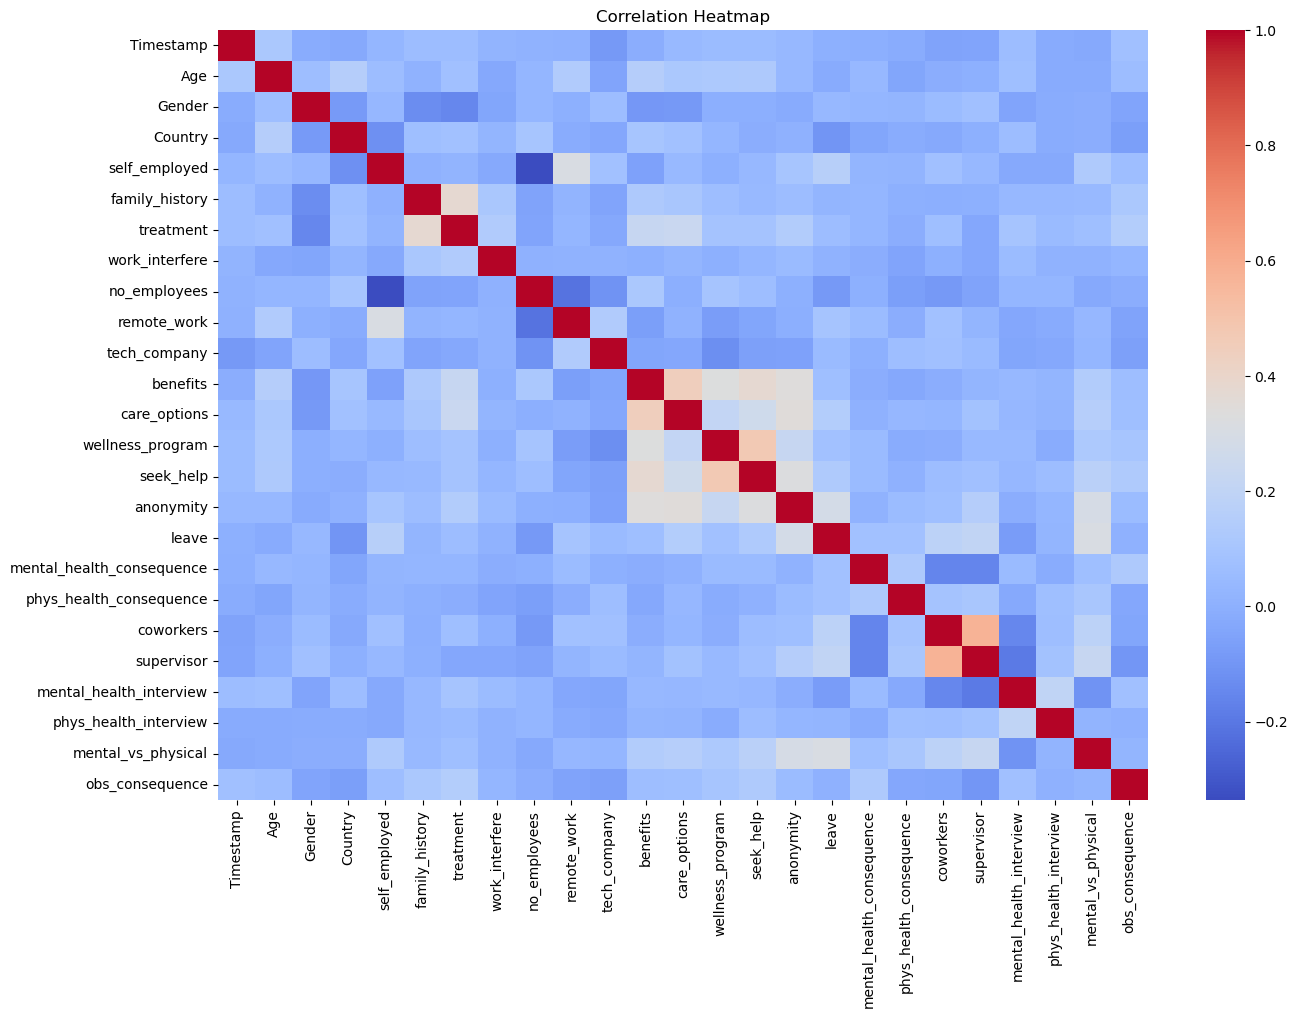

In [52]:
plt.figure(figsize=(15,10))

sns.heatmap(df.corr(), cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

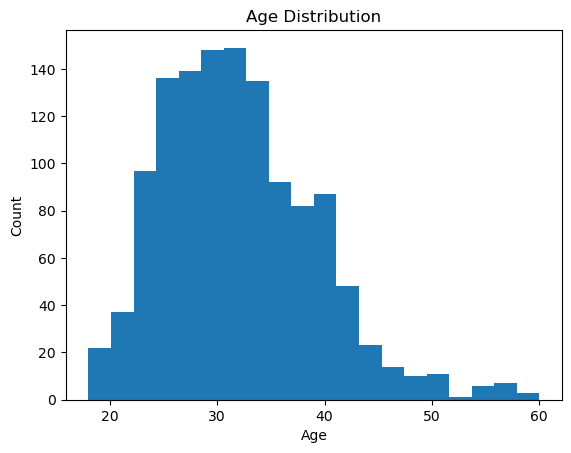

In [54]:
plt.hist(df['Age'], bins=20)

plt.title("Age Distribution")

plt.xlabel("Age")

plt.ylabel("Count")

plt.show()

In [56]:
X = df.drop('treatment', axis=1)

y = df['treatment']

In [58]:
from sklearn.model_selection import train_test_split

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [62]:
from sklearn.linear_model import LogisticRegression

In [68]:
log_model = LogisticRegression(max_iter=5000)

In [70]:
log_model.fit(X_train, y_train)

LogisticRegression(max_iter=5000)

In [72]:
y_pred_log = log_model.predict(X_test)

In [74]:
from sklearn.metrics import accuracy_score

In [77]:
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)

Logistic Regression Accuracy: 0.688


In [79]:
from sklearn.ensemble import RandomForestClassifier

In [81]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [83]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [85]:
y_pred_rf = rf_model.predict(X_test)

In [87]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.732


In [89]:
from sklearn.metrics import confusion_matrix

In [91]:
cm = confusion_matrix(y_test, y_pred_rf)

print(cm)

[[85 26]
 [41 98]]


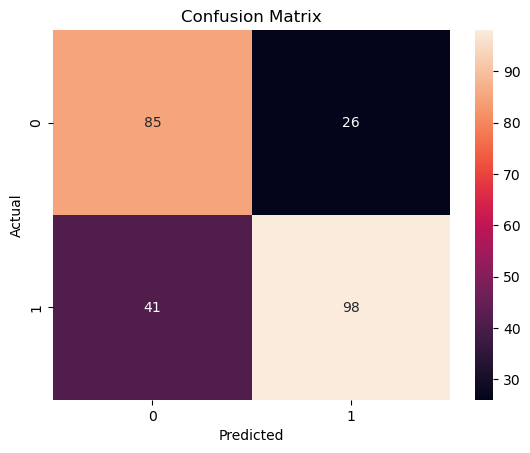

In [93]:
sns.heatmap(cm, annot=True, fmt='d')

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [95]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.67      0.77      0.72       111
           1       0.79      0.71      0.75       139

    accuracy                           0.73       250
   macro avg       0.73      0.74      0.73       250
weighted avg       0.74      0.73      0.73       250



In [97]:
importance = rf_model.feature_importances_

features = X.columns

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

importance_df = importance_df.sort_values(by='Importance', ascending=False)

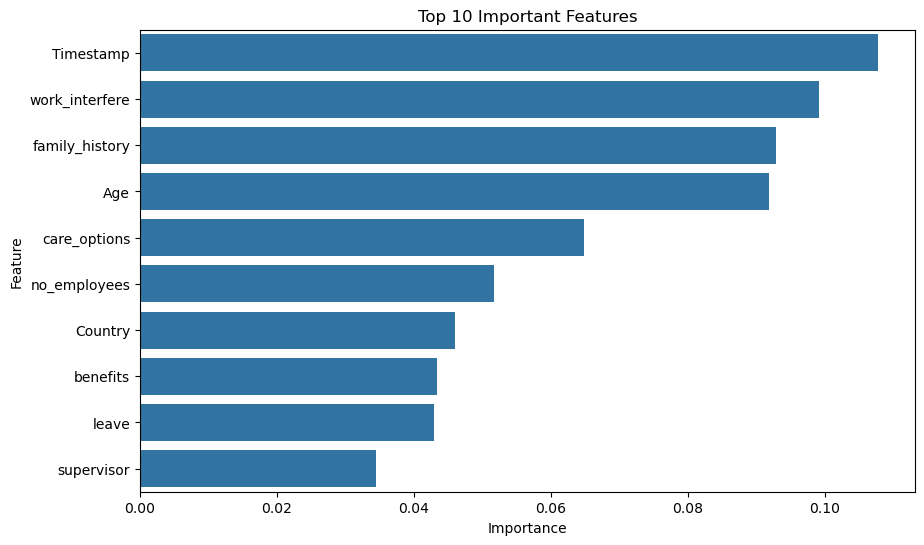

In [99]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df.head(10)
)

plt.title("Top 10 Important Features")

plt.show()

In [101]:
sample = X_test.iloc[0]

In [105]:
sample_df = pd.DataFrame([sample])

prediction = rf_model.predict(sample_df)

print(prediction)

[1]


In [107]:
if prediction[0] == 1:
    print("Person may need mental health treatment")
else:
    print("Person may not need mental health treatment")


Person may need mental health treatment
